In [1]:
"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #03 - Statistical Objective Analysis

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using statistical objective analysis.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"
__StudentName__ = 'Austin Portner'

In [2]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles

In [3]:
### Read in observations ###
path = 'C:/Users/austi/Desktop/AtSc_Masters_Classes/AtSc_528/Function_Fitting/'
file = 'RAOBs_201903131200.txt'
#path+file

In [4]:
### Set up analysis map with a 21x27 rectangular grid of points ###
# From hw2
lats, lons, hgts = [], [], []

with open(path+file, 'r') as f:
    for line in f:
        parts = line.strip().split(',')
        if len(parts) >=6:
            try:
                lat = float(parts[1])
                lon = float(parts[2])
                hgt = float(parts[3])
                wdir = float(parts[4])
                wspd = float(parts[5])
                # append valid observation data
                if not (np.isnan(hgt) or np.isnan(wdir) or np.isnan(wspd)):
                    lats.append(lat)
                    lons.append(lon)
                    hgts.append(hgt)
            except ValueError:
                continue

#Conversion to np arrays
obs_lat = np.array(lats)
obs_lon = np.array(lons)
obs_hgt = np.array(hgts)

# Now to setip 21x27 analysis grid
y, x = 27, 21
dx, dy = 1.27, 1.27 #in cm
x0, y0 = 25.0, -15.5 #in cm

# Now to generate 1D vectors and 2D meshgrid
grid_x_1d = x0 + np.arange(x) * dx
grid_y_1d = y0 + np.arange(y) * dy

grid_x_map, grid_y_map = np.meshgrid(grid_x_1d, grid_y_1d, indexing = 'ij')

In [5]:
### convert obs lat/long to x,y ###
# From hw2
lambda_0 = -100.0
phi_0 = 60.0
rho = 6371000.0 
m = 1 / 15000000
R = rho * 100.0 * m

# Angles from lat/lon to radians
lat_rad = np.radians(obs_lat)
lon_rad = np.radians(obs_lon)
lambda_0_rad = np.radians(lambda_0)
phi_0_rad = np.radians(phi_0)

#conversion to cartesian coordinates in cm
sigma_obs = (1.0 + np.sin(phi_0_rad)) / (1.0 + np.sin(lat_rad))
obs_x = R * sigma_obs * np.cos(lat_rad) * np.cos(lon_rad - lambda_0_rad)
obs_y = R * sigma_obs * np.cos(lat_rad) * np.sin(lon_rad - lambda_0_rad)

###*** All of the above code came from previous homeworks***###

In [6]:
# Barnes Analysis

Kd = 10.8844524 # cm^2
re = 12.7775892 # cm

# Background initialization
nx, ny = grid_x_map.shape
background = np.zeros_like(grid_x_map)
for i in range(nx):
    for j in range(ny):
        d_sq = (grid_x_map[i, j] - obs_x)**2 + (grid_y_map[i, j] - obs_y)**2
        mask = d_sq <= re**2
        if np.any(mask):
            w = np.exp(-d_sq[mask] / Kd)
            background[i, j] = np.sum(w * obs_hgt[mask]) / np.sum(w)
        else:
            background[i, j] = np.mean(obs_hgt)

# now for Forward interpolation to allow for correct N values
def bilinear_interp_2d(x_1d, y_1d, grid_2d, px, py):
    i = np.clip(np.searchsorted(x_1d, px) - 1, 0, len(x_1d) - 2)
    j = np.clip(np.searchsorted(y_1d, py) - 1, 0, len(y_1d) - 2)
    x1, x2 = x_1d[i], x_1d[i + 1]
    y1, y2 = y_1d[j], y_1d[j + 1]
    tx = (px - x1) / (x2 - x1)
    ty = (py - y1) / (y2 - y1)
    return ((1 - tx) * (1 - ty) * grid_2d[i, j] + tx * (1 - ty) * grid_2d[i + 1, j] +
    (1 - tx) * ty * grid_2d[i, j + 1] + tx * ty * grid_2d[i + 1, j + 1])

def barnes_using_grid(grid_2d, px, py):
    """ Single pass Barnes of grid values at (px, py)"""
    d_sq = (grid_x_map - px)**2 + (grid_y_map - py)**2
    mask = d_sq <= re**2
    if np.any(mask):
        w = np.exp(-d_sq[mask] / Kd)
        return np.sum(w * grid_2d[mask]) / np.sum(w)
    return grid_2d.flat[np.argmin(d_sq)]

def forward_interp(grid_2d, px, py):
    """ Bilinear interpolation inside the grid, Barnes outside grid"""
    inside = (grid_x_1d[0] <= px <= grid_x_1d[-1]) and (grid_y_1d[0] <= py <= grid_y_1d[-1])
    if inside:
        return bilinear_interp_2d(grid_x_1d, grid_y_1d, grid_2d, px, py)
    return barnes_using_grid(grid_2d, px, py)

In [7]:
#print(background_obs)
#print(background)

In [8]:
# Now to perform Statistical Objective Analysis

# Background at obs using forward interp
background_obs = np.array([forward_interp(background, obs_x[k], obs_y[k])
                                          for k in range(len(obs_x))])
innovations = obs_hgt - background_obs

In [9]:
# Now to do Schlatter Correlation

# This takes care of image scale factor
phi_target_deg = 40.0
stereo_factor = (1.0 + np.sin(np.radians(phi_0))) / (1.0 + np.sin(np.radians(phi_target_deg)))
m_40 = m * stereo_factor

# This will put b' in cm^-2
b_prime = 1.24 / (m_40 * 1e8)**2

def schlatter_corr(d_cm):
    """
    This will compute Schlatter background error correlation model
    handles correlation to be when d = 0 it will return 1 instead of 0.95
    """
    corr = 0.95 * np.exp(-b_prime * d_cm**2)
    if isinstance(d_cm, np.ndarray):
        corr[d_cm == 0.0] = 1.0
    else:
        if d_cm == 0.0:
            corr = 1.0
    return corr

In [10]:
# Now to perform 3 analysis with n = 2, n = 4, and n = 10

N_values = [2 , 4, 10]
analysis_grids = {}
increment_grids = {}

for N in N_values:
    print(f"running SOA for N = {N}")
    analysis_grid = np.zeros_like(grid_x_map)
    for i in range(nx):
        for j in range(ny):
            gx = grid_x_map[i, j]
            gy = grid_y_map[i, j]
            
            # d^2 from grid pt to obs
            d_sq_grid = (gx - obs_x)**2 + (gy - obs_y)**2
            
            # Finding the closest obs to each other
            closest_indices = np.argsort(d_sq_grid)[:N]
            
            sub_obs_x = obs_x[closest_indices]
            sub_obs_y = obs_y[closest_indices]
            sub_innovations = innovations[closest_indices]
            
            # Building P matrix using Schlatter
            dist_mat = np.sqrt((sub_obs_x[:, None] - sub_obs_x[None, :])**2 + (sub_obs_y[:, None] - sub_obs_y[None, :])**2)
            P_matrix_schlatter = schlatter_corr(dist_mat)
        
            # Building rho vector using Schlatter
            dist_grid_obs = np.sqrt((sub_obs_x - gx)**2 + (sub_obs_y - gy)**2)
            rho_vector = schlatter_corr(dist_grid_obs)
            
            try:
                # Solving P * w = rho for optimal weights
                weights = np.linalg.solve(P_matrix_schlatter, rho_vector)
                
                # Analysis eq: f_A = f_B + sum(w_k * innovation_k)
                analysis_grid[i, j] = background[i, j] + np.sum(weights * sub_innovations)
            except np.linalg.LinAlgError:
                analysis_grid[i, j] = background[i, j]
                
    analysis_grids[N] = analysis_grid
    # increment field for this: analysis - background
    increment_grids[N] = analysis_grid - background

running SOA for N = 2
running SOA for N = 4
running SOA for N = 10


In [11]:
#print(analysis_grids[2])

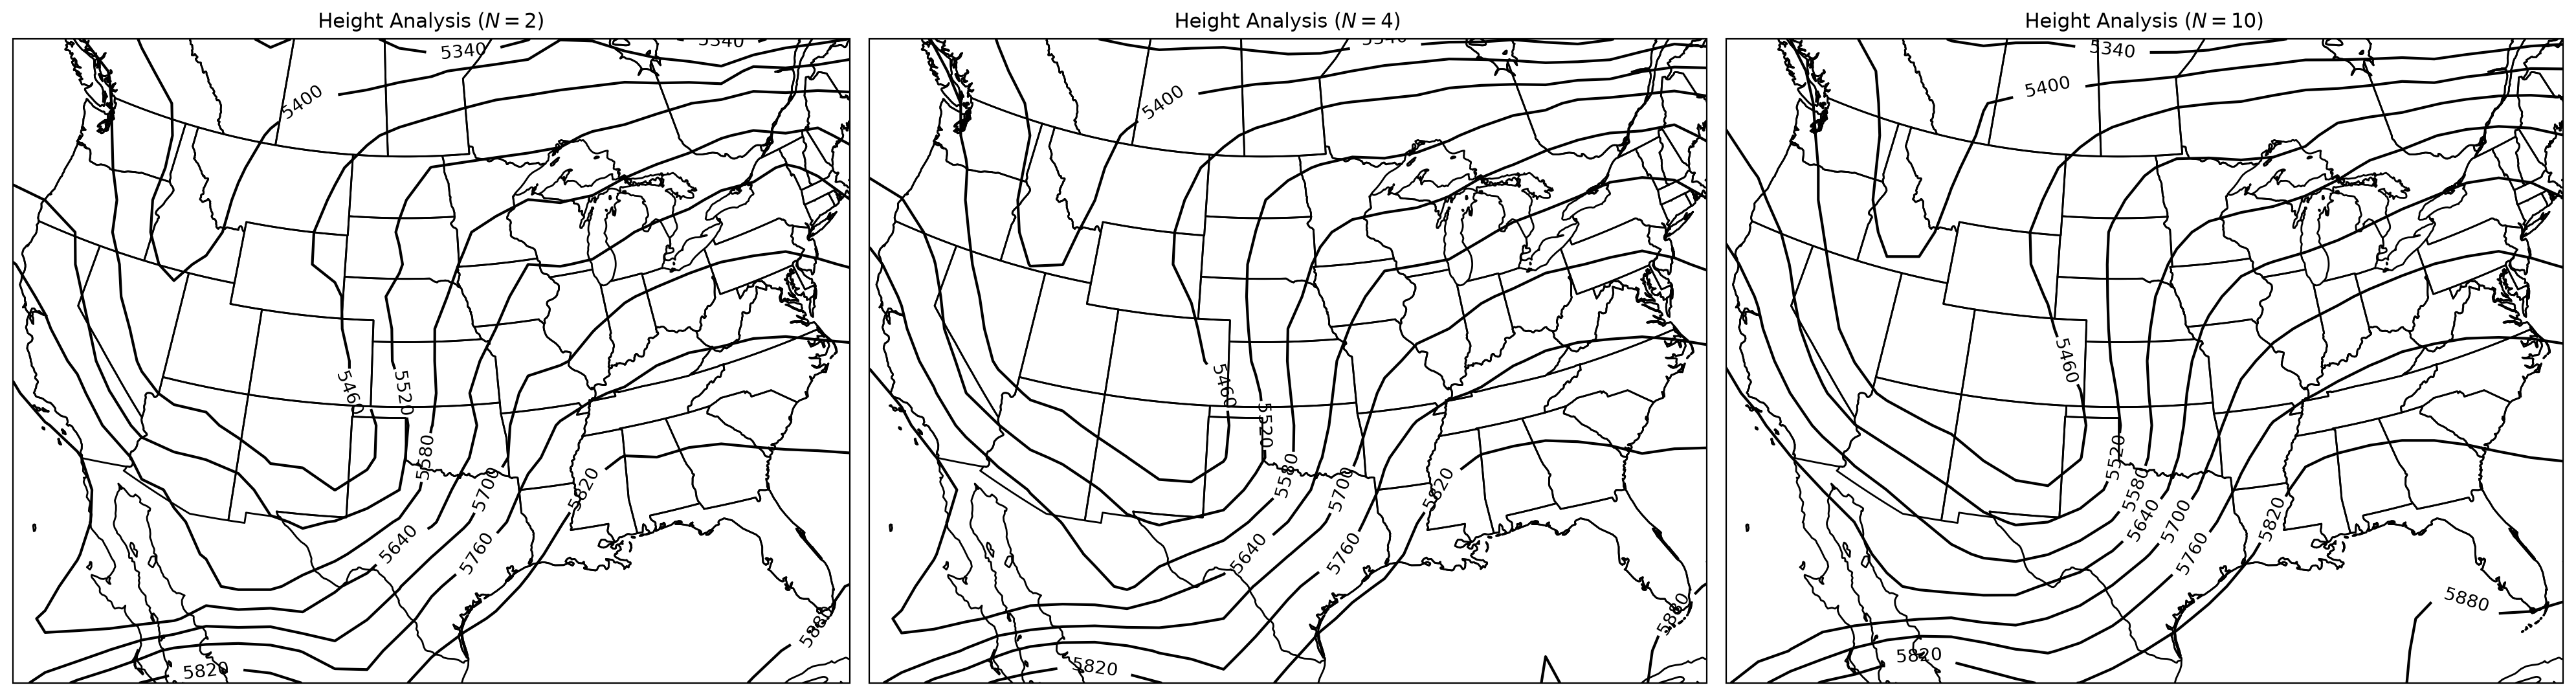

In [12]:
# Now to plot everything beginning with analysis fields

globe = ccrs.Globe(ellipse=None, semimajor_axis=rho, semiminor_axis=rho)
proj = ccrs.Stereographic(central_longitude=lambda_0, central_latitude=90, true_scale_latitude=phi_0, globe=globe)

fig, axes = plt.subplots(1, 3, figsize=(20, 7), dpi=200, subplot_kw={'projection': proj})

analyses = [analysis_grids[2], analysis_grids[4], analysis_grids[10]]
titles = [
    'Height Analysis ($N = 2$)',
    'Height Analysis ($N = 4$)',
    'Height Analysis ($N = 10$)'
]
levels = np.arange(4800, 6000, 60)

for ax, analysis, title in zip(axes, analyses, titles):
    ax.add_feature(cfeature.STATES)
    ax.add_feature(cfeature.COASTLINE)
    
    cs1 = ax.contour(grid_y_map / m / 100, -grid_x_map / m / 100, analysis, colors='k', levels=levels, transform=proj)
    ax.clabel(cs1, levels=levels, fmt='%d')
    ax.set_title(title, fontsize=11)

plt.tight_layout()
plt.savefig('statistical_analysis_all_N.png', dpi=300, bbox_inches='tight')
plt.show()

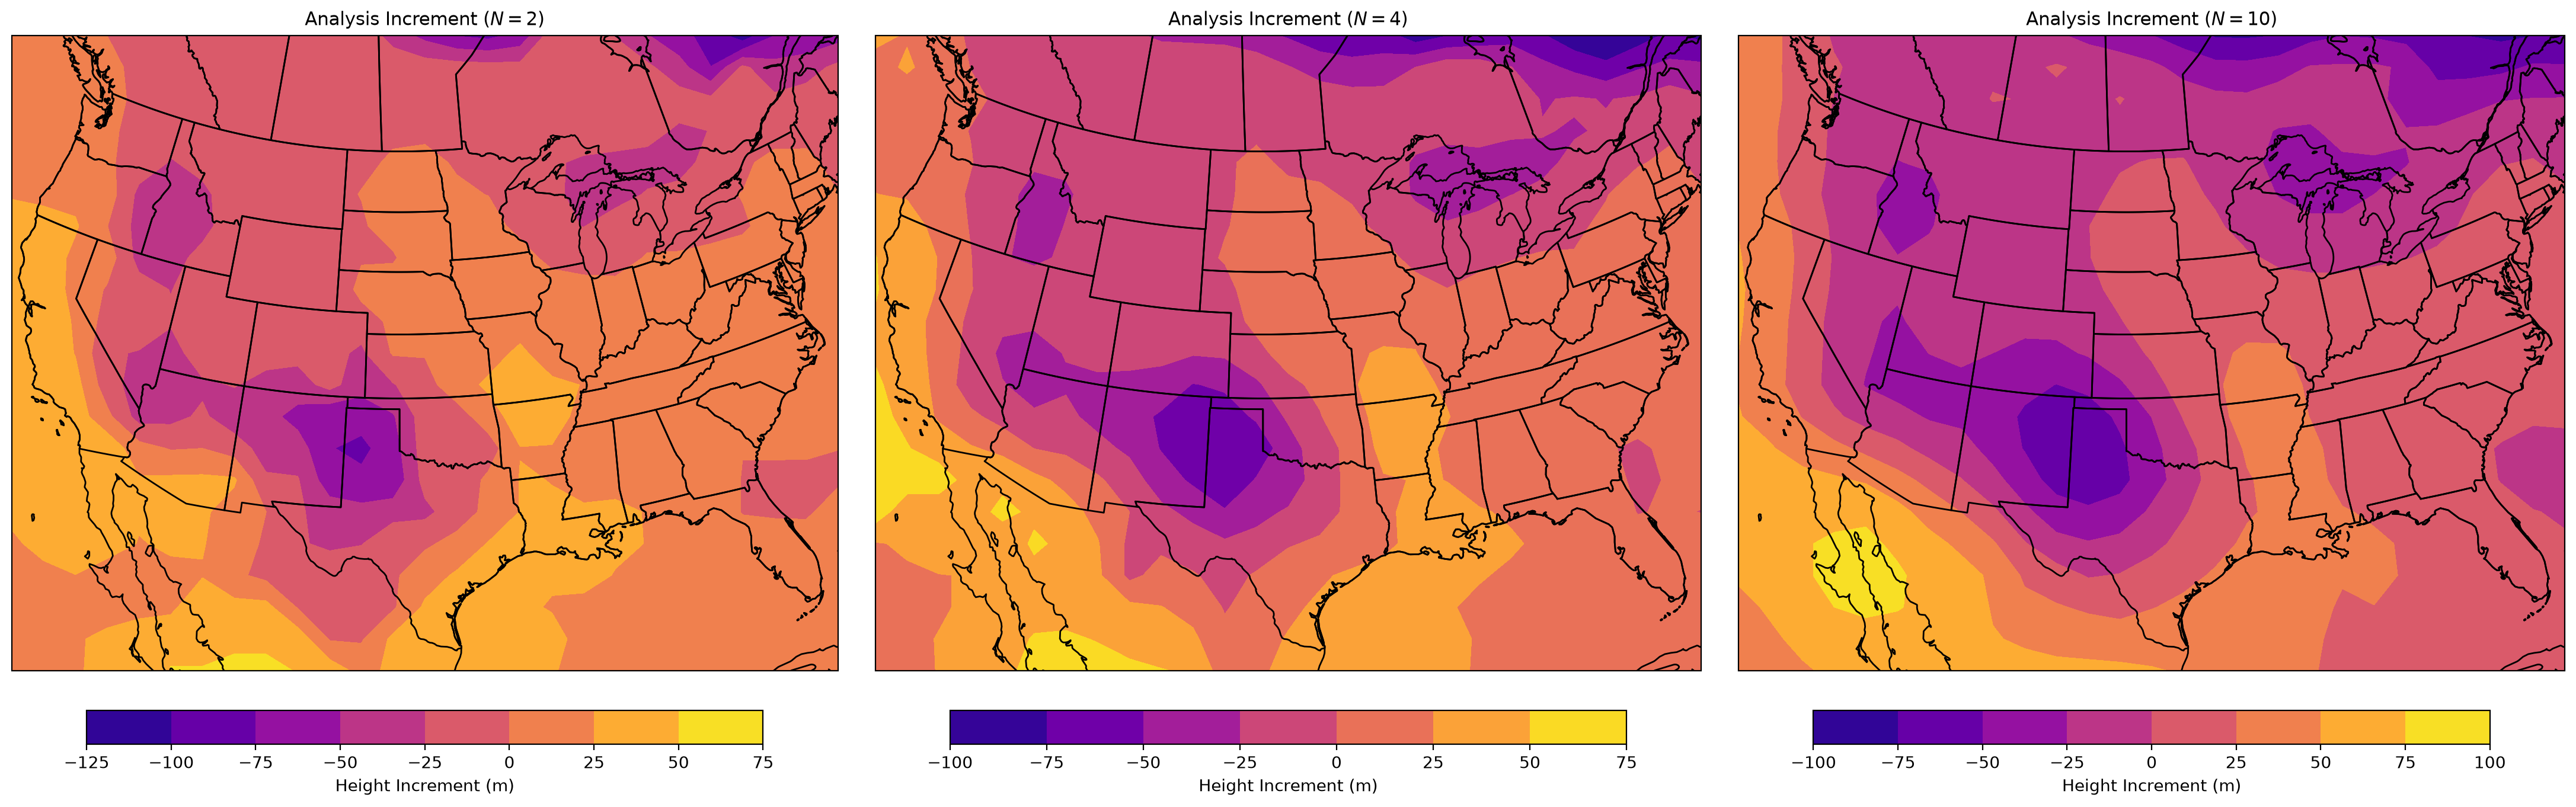

In [13]:
# Plot for analysis increment fields

fig, axes = plt.subplots(1, 3, figsize=(22, 7), dpi=200, subplot_kw={'projection': proj})

increments = [increment_grids[2], increment_grids[4], increment_grids[10]]
increment_titles = [
    'Analysis Increment ($N = 2$)',
    'Analysis Increment ($N = 4$)',
    'Analysis Increment ($N = 10$)'
]

for ax, inc, title in zip(axes, increments, increment_titles):
    ax.add_feature(cfeature.STATES)
    ax.add_feature(cfeature.COASTLINE)
    
    cf = ax.contourf(grid_y_map / m / 100, -grid_x_map / m / 100, inc, cmap='plasma', transform=proj)
    fig.colorbar(cf, ax=ax, orientation='horizontal', pad=0.05, shrink=0.8, label='Height Increment (m)')
    ax.set_title(title, fontsize=11)

plt.tight_layout()
plt.savefig('analysis_increments_all_N.png', dpi=300, bbox_inches='tight')
plt.show()

In [17]:
# Analysis Differences and RMSD
rmsd = {}

for N in N_values:
    analysis_grid = analysis_grids[N]
    increment_grid = increment_grids[N]
    
    forward_interp_values = np.zeros(len(obs_x))
    for k in range(len(obs_x)):
        ox = obs_x[k]
        oy = obs_y[k]
        
        # Bilinear interpolation for obs stations within domain
        if (grid_x_1d[0] <= ox <= grid_x_1d[-1]) and (grid_y_1d[0] <= oy <= grid_y_1d[-1]):
            val = bilinear_interp_2d(grid_x_1d, grid_y_1d, analysis_grid, ox, oy)
            if val is not None:
                forward_interp_values[k] = val
            else:
                # Fallback to one-pass Barnes scheme if interpolation returns None
                d_sq = (grid_x_map - ox)**2 + (grid_y_map - oy)**2
                valid_mask = d_sq <= re**2
                if np.any(valid_mask):
                    d_sq_valid = d_sq[valid_mask]
                    grid_values_valid = analysis_grid[valid_mask]
                    weights = np.exp(-d_sq_valid / Kd)
                    forward_interp_values[k] = np.sum(weights * grid_values_valid) / np.sum(weights)
                else:
                    forward_interp_values[k] = np.nan
        else:
            # 2. One-pass Barnes scheme for observation stations outside the grid domain[cite: 41]
            d_sq = (grid_x_map - ox)**2 + (grid_y_map - oy)**2
            valid_mask = d_sq <= re**2
            if np.any(valid_mask):
                d_sq_valid = d_sq[valid_mask]
                grid_values_valid = analysis_grid[valid_mask]
                weights = np.exp(-d_sq_valid / Kd)
                forward_interp_values[k] = np.sum(weights * grid_values_valid) / np.sum(weights)
            else:
                forward_interp_values[k] = np.nan
    # Analysis diff at each station (NaN where forward interp not possible)
    station_diffs = forward_interp_values - obs_hgt
    valid = ~np.isnan(station_diffs)
    # Put this in to ensure it did not use stations outside grid.
    #print(f"  stations used in RMSD: {valid.sum()} of {len(obs_x)}")
    
    #RMS Diffs between analysis and obs
    rms_value = np.sqrt(np.mean(station_diffs[valid]**2))
    rmsd[N] = rms_value
    print(f"RMS for N = {N}: {rms_value:.8f} m")
    
    # Saving each file
    np.savetxt(f'analysis_N{N}.txt', analysis_grid, fmt='%.4f', header=f'Statistical Objective Analysis Raw Heights (N={N})')
    np.savetxt(f'analysis_increment_N{N}.txt', increment_grid, fmt='%.4f', header=f'Analysis Increment Raw Values (N={N})')
    np.savetxt(f'station_diffs_N{N}.txt', station_diffs, fmt='%.4f', header=f'Analysis Differences (Analysis - Obs) at Stations (N={N})')

# Saves RMSD
with open('rmsD.txt', 'w') as f:
    f.write("N_value\tRMSD (m)\n")
    for N, rms in rmsd.items():
        f.write(f"{N}\t{rms:.8f}\n")

RMS for N = 2: 63.20586309 m
RMS for N = 4: 60.40765702 m
RMS for N = 10: 62.26539711 m


In [18]:
### In a separte text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.
    
    The general features show a large trough over the western U.S. and a ridge over the eastern U.S. There are tighly compact contours over Texas.
    The tight packing of contours over Texas are indicative of jet stream location. The largest negative values for the increment field are over the
    Oklahoma and Texas panhandle. The increments are positive in the southeast and in the Gulf. Towards the top of the ridge we see negative values
    again over the Great Lakes region.
   
2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?

    The contours from N = 2 to N = 10 keep getting smoother as N gets larger. This makes sense since more stations get used as N increases. The error
    on N = 2 feeds into the analysis more than on N = 4 and N = 10. On N = 10, the nearest-station changes to the 10 nearest stations. This gradually
    changes as we go through each point and errors begin to average out which makes the field vary smoothly. The kinks in N = 2 analysis are present on
    both the analysis increment and height analysis plots. The smoothing is seen on both plots as well. N = 4 was our "happy medium" here as errors did
    not fully average out, but there was less error fed into the analysis than in N = 2. This made a smoother plot than N = 2, but it still had smaller
    kinks compared to N = 10.

3 - What happens as you increase the number of points considered for the analysis?  Is this 
    desirable?  Why or why not?

    As N increases, the analysis is smoother and more coherent spatially. This means the influence of any one station, and errors associated
    with that station, becomes smaller. The observations becomes less closely fit as N increases. This can be desireable when we look at synoptic
    flow. This is due to the fact that the larger scale flow will be less sensitive to a single bad observation. When looking at smaller scale flow,
    it is less desireable because the data is fit less closely as N increases. 
    
'''

'\n1 - Describe the general features that you see in your contoured analyses.\n    \n    The general features show a large trough over the western U.S. and a ridge over the eastern U.S. There are tighly compact contours over Texas.\n    The tight packing of contours over Texas are indicative of jet stream location. The largest negative values for the increment field are over the\n    Oklahoma and Texas panhandle. The increments are positive in the southeast and in the Gulf. Towards the top of the ridge we see negative values\n    again over the Great Lakes region.\n   \n2 - Describe the differences that you see in your contoured analyses.  \n    Does one analysis seem to be smoother than the other?  If so, what would cause this?\n\n    The contours from N = 2 to N = 10 keep getting smoother as N gets larger. This makes sense since more stations get used as N increases. The error\n    on N = 2 feeds into the analysis more than on N = 4 and N = 10. On N = 10, the nearest-station changes 